In [1]:
import numpy as np
from matplotlib import pyplot as plt
import enlighten
import shapely

from scipy.interpolate import interp1d

from utils import Modulator_CPS


from imodulator.ChargeSimulator import ChargeSimulatorSolcore
from imodulator.OpticalSimulator import OpticalSimulatorFEMWELL, OpticalSimulatorMODE
from imodulator.ElectroOpticalSimulator import ElectroOpticalSimulator
from imodulator.RFSimulator import RFSimulatorFEMWELL as RFSimulator

from utils_data_analysis import get_EO
import skrf as rf

import os
import json

%matplotlib widget

Failed to import lumapi: [Errno 2] No such file or directory: 'C:/Program Files/Lumerical/v232/api/python/lumapi.py'


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\registries.py:73: UserWarning: Optics solver 'RCWA' will not be available. An installation of S4 has not been found.
  warn(
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\nextnanopy\defaults.py:202: UserWarning: Unsupported products in config file: ['nextnano.NEGF++'] will be ignored. To not see this message, please remove unsupported products from the config file: C:\Users\20230622\.nextnanopy-configNote: nextnano.NEGF++ was renamed to nextnano.NEGF, nextnano.NEGF was renamed to nextnano.NEGF_classic. Please check the documentation for more details.
  warnings.warn(


Successfully imported nextnanopy
Successfully configured nextnano++ settings
  [OK] nextnano++ exe: C:/Program Files/nextnano/2026_07_03/nextnano++/bin/nextnano++_Intel_64bit.exe
  [OK] nextnano++ license: C:/Users/20230622/OneDrive - TU Eindhoven/PhD/License_nnp.lic
  [OK] nextnano++ database: C:/Program Files/nextnano/2026_07_03/nextnano++/database/database.nnp
  [OK] nextnano++ outputdirectory: D:/Repos/imodulator/tests\nn_output
nextnano configuration test passed: all paths are valid.


# Initialize the device

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)


(<Figure size 640x480 with 1 Axes>, <Axes: >)

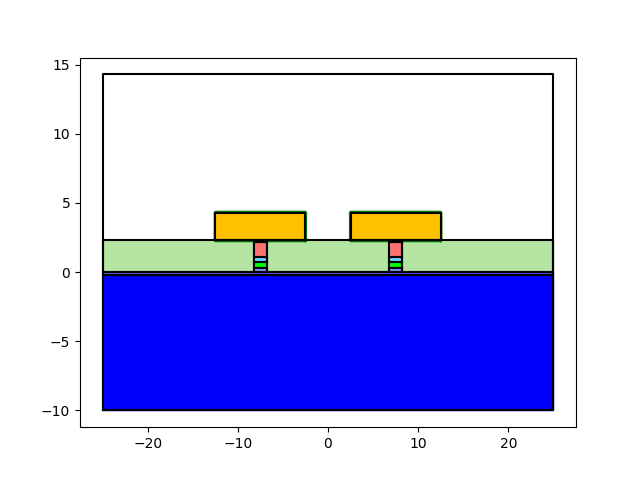

In [2]:
modulator = Modulator_CPS()

poly_color_dict = {
		"substrate": (0,0,255),
		"L1": (79,79,255),
		"L2": (147,147,255),
		"L3": (0,255,0),
		"L4": (113,208,255),
		"L5": (255,113,113),
		"L6": (192,0,0),
		"sig_metal": (255,192,0),
		"bcbp_left": (180,229,162),
		"bcbp_right": (180,229,162),
		"sig_metal_right": (255,192,0),
		"L1_right": (79,79,255),
        "L2_right": (147,147,255),
        "L3_right": (0,255,0),
        "L4_right": (113,208,255),
        "L5_right": (255,113,113),
        "L6_right": (192,0,0),
		"bcbp_right_right": (180,229,162),
    }

for label, color in poly_color_dict.items():
    poly_color_dict[label] = tuple(np.array(color)/255)

modulator.device.plot_polygons(
	fill_polygons=True,
	poly_list_color=poly_color_dict,
    alpha_polygons = 1
)

# Optical mode solving

In [3]:
for poly in modulator.device.photo_polygons:
    # print(poly.name)
# poly = modulator.device.photo_polygons[2]
# print(poly.name)
    print(poly.optical_material(1.55))

(11.259-115.13j)
(12.455063192798999-0.5393769399999999j)
(10.044188694235292-0.00017800641226154557j)
(10.045374734118742-3.560338446888203e-05j)
(11.271013253046425-7.49569754604628e-06j)
(10.040964315114422-1.4590546011706262e-05j)
2.4336
(11.259-115.13j)
(12.455063192798999-0.5393769399999999j)
(10.044188694235292-0.00017800641226154557j)
(10.045374734118742-3.560338446888203e-05j)
(11.271013253046425-7.49569754604628e-06j)
(10.040964315114422-1.4590546011706262e-05j)
(9.83999420181408-0.0008071904786066097j)
2.4336
2.4336
(10.024793973028872+0j)
1


25678


(<Figure size 800x400 with 4 Axes>,
 [<Axes: title={'center': '$\\epsilon_{xx}$ real part'}, xlabel='x (um)', ylabel='y (um)'>,
  <Axes: title={'center': '$\\epsilon_{xx}$ imaginary part'}, xlabel='x (um)', ylabel='y (um)'>])

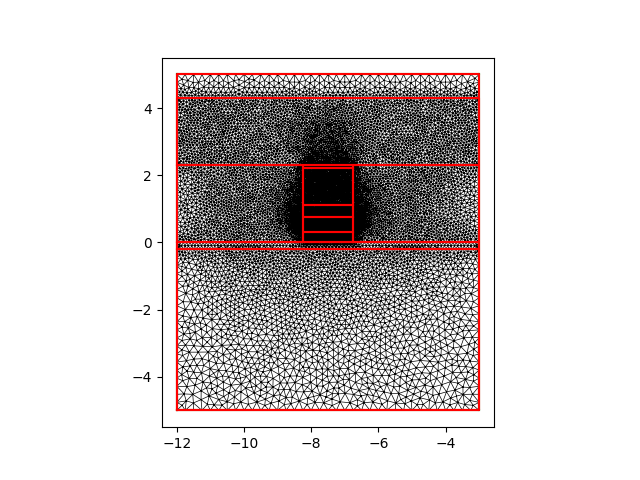

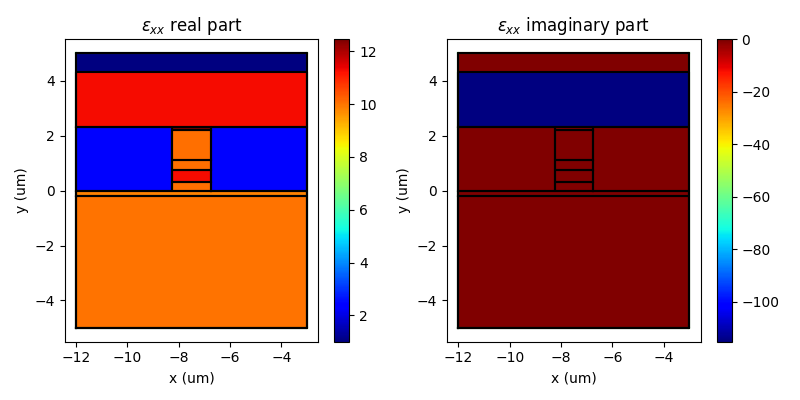

In [5]:
mode = OpticalSimulatorFEMWELL(
            device=modulator.device,
            # simulation_window=shapely.box(-10, -3, -modulator.metal_sep/2 - modulator.w_metal_sig/2,5),
			simulation_window=shapely.box(-10-2, -5, -5+2,5),
            include_metals=True
        )
mode.make_mesh()
mode.plot_mesh()

print(mode.mesh.nelements)

mode.plot_epsilon_optical()

To find the group index we will compute the optical mode at different wavelengths and then compute the group index based on this local derivative.

In [6]:
wl_values = np.linspace(1.5,1.6,11)

neff_TE = []
neff_TM = []

modes_1550 = None
for wl in wl_values:
    modes = mode.compute_modes(
        wavelength=wl,
        num_modes=4,
        order=1,
        metallic_boundaries=["top", "bottom", "left", "right"],
        n_guess=3.2,
        return_modes=True
    )
    if np.isclose(wl, 1.55):
        modes_1550 = modes
    
    te_frac = [mode.te_fraction for mode in modes]

    mode_idx = np.argmax(np.asarray(te_frac) > 0.5)

    neff_TE.append(modes[mode_idx].n_eff.real)

    print(f"Selected mode at {wl} nm: mode {mode_idx} with n_eff = {modes[mode_idx].n_eff.real:.4f} and TE fraction = {modes[mode_idx].te_fraction:.4f} and loss = {modes[mode_idx].calculate_propagation_loss(1e4):.2f} dB/cm")

    tm_frac = [mode.tm_fraction for mode in modes]
    mode_idx = np.argmax(np.asarray(tm_frac) > 0.5)
    neff_TM.append(modes[mode_idx].n_eff.real)
    print(f"Selected mode at {wl} nm: mode {mode_idx} with n_eff = {modes[mode_idx].n_eff.real:.4f} and TM fraction = {modes[mode_idx].tm_fraction:.4f} and loss = {modes[mode_idx].calculate_propagation_loss(1e4):.2f} dB/cm")

    # for i in range(len(modes)):
    #     print(f'Effective index - mode {i}: {modes[i].n_eff.real:.4f}')
    #     print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
    #     print(f"power: ", modes[i].calculate_power())
    #     print(f"TE fraction: ", modes[i].te_fraction)
    #     print(f"TM fraction: ", modes[i].tm_fraction)
    #     print(f"transversality: {modes[i].transversality}")
    #     print('#------------------------------------------#')

Selected mode at 1.5 nm: mode 0 with n_eff = 3.2328 and TE fraction = 0.9997
Selected mode at 1.5 nm: mode 1 with n_eff = 3.2314 and TM fraction = 0.9997 and loss = 3.79 dB/cm
Selected mode at 1.51 nm: mode 0 with n_eff = 3.2295 and TE fraction = 0.9997
Selected mode at 1.51 nm: mode 1 with n_eff = 3.2283 and TM fraction = 0.9997 and loss = 4.12 dB/cm
Selected mode at 1.52 nm: mode 0 with n_eff = 3.2263 and TE fraction = 0.9997
Selected mode at 1.52 nm: mode 1 with n_eff = 3.2252 and TM fraction = 0.9997 and loss = 4.48 dB/cm
Selected mode at 1.53 nm: mode 0 with n_eff = 3.2232 and TE fraction = 0.9997
Selected mode at 1.53 nm: mode 1 with n_eff = 3.2222 and TM fraction = 0.9997 and loss = 4.87 dB/cm
Selected mode at 1.54 nm: mode 0 with n_eff = 3.2201 and TE fraction = 0.9997
Selected mode at 1.54 nm: mode 1 with n_eff = 3.2193 and TM fraction = 0.9997 and loss = 5.29 dB/cm
Selected mode at 1.55 nm: mode 0 with n_eff = 3.2171 and TE fraction = 0.9997
Selected mode at 1.55 nm: mode 1 w

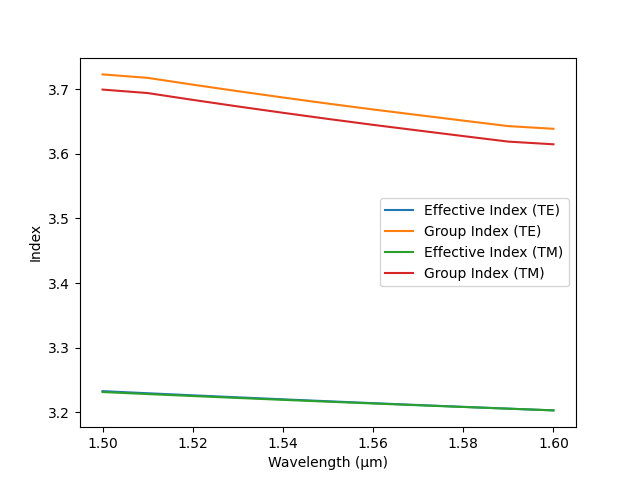

In [7]:
neff_TE = np.array(neff_TE)
neff_TM = np.array(neff_TM)

dneff_dwl_TE = np.gradient(neff_TE, wl_values)
ng_TE = neff_TE - wl_values * dneff_dwl_TE


dneff_dwl_TM = np.gradient(neff_TM, wl_values)
ng_TM = neff_TM - wl_values * dneff_dwl_TM

plt.figure()
plt.plot(wl_values, neff_TE, label='Effective Index (TE)')
plt.plot(wl_values, ng_TE, label='Group Index (TE)')

plt.plot(wl_values, neff_TM, label='Effective Index (TM)')
plt.plot(wl_values, ng_TM, label='Group Index (TM)')

plt.xlabel('Wavelength (μm)')
plt.ylabel('Index')
plt.legend()
plt.show()


In [10]:
from skfem import ElementVector, ElementDG, ElementTriP1

opt_mode_TE = modes_1550[0]
opt_mode_TM = modes_1550[1]

(mfield_t, mfield_t_basis), (mfield_n, mfield_n_basis) = opt_mode_TE.basis.split(opt_mode_TE.E)
plot_basis = mfield_t_basis.with_element(ElementVector(ElementDG(ElementTriP1())))
mfield_xy = plot_basis.project(-np.real(mfield_t_basis.interpolate(mfield_t)))
(mfield_x_TE, mfield_x_basis), (mfield_y_TE, mfield_y_basis) = plot_basis.split(mfield_xy)

(mfield_t, mfield_t_basis), (mfield_n, mfield_n_basis) = opt_mode_TM.basis.split(opt_mode_TM.E)
plot_basis = mfield_t_basis.with_element(ElementVector(ElementDG(ElementTriP1())))
mfield_xy = plot_basis.project(-np.real(mfield_t_basis.interpolate(mfield_t)))
(mfield_x_TM, mfield_x_basis), (mfield_y_TM, mfield_y_basis) = plot_basis.split(mfield_xy)

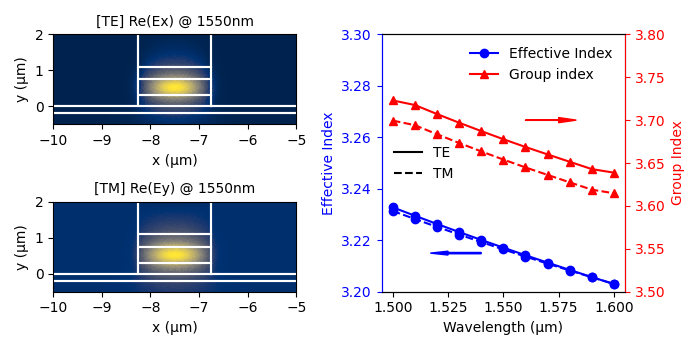

In [19]:
fig = plt.figure(figsize = (7,3.5))
gs = fig.add_gridspec(2, 2)

ax_field_TE = fig.add_subplot(gs[0, 0])
ax_field_TM = fig.add_subplot(gs[1, 0])
ax_neff = fig.add_subplot(gs[:, 1])
ax_ng = ax_neff.twinx()

mfield_x_basis.plot(mfield_x_TE, ax = ax_field_TE, cmap = 'cividis')
mode.plot_polygons(fig = fig, ax = ax_field_TE, color_polygon = 'white')

ax_field_TE.set_xlim(-10,-5)
ax_field_TE.set_ylim(-0.5,2)
ax_field_TE.set_xlabel('x (μm)')
ax_field_TE.set_ylabel('y (μm)')
ax_field_TE.set_title('[TE] Re(Ex) @ 1550nm', fontsize=10)

mfield_y_basis.plot(-mfield_y_TM, ax = ax_field_TM, cmap = 'cividis')
mode.plot_polygons(fig = fig, ax = ax_field_TM, color_polygon = 'white')
ax_field_TM.set_xlim(-10,-5)
ax_field_TM.set_ylim(-0.5,2)
ax_field_TM.set_xlabel('x (μm)')
ax_field_TM.set_ylabel('y (μm)')
ax_field_TM.set_title('[TM] Re(Ey) @ 1550nm', fontsize=10)

neff_color = 'blue'
ng_color = 'red'
ax_neff.plot(wl_values, neff_TE, label='Effective Index', marker = 'o', color = neff_color)
ax_neff.plot(wl_values, neff_TM, marker = 'o', color = neff_color, linestyle = 'dashed')
ax_neff.plot([],[], label = "Group index", marker = '^', color = ng_color)
ax_neff.legend(frameon=False, loc='best')
ax_ng.plot(wl_values, ng_TE, marker = '^', color = ng_color)
ax_ng.plot(wl_values, ng_TM, marker = '^', color = ng_color, linestyle = 'dashed')

ax_ng.plot([],[], label = 'TE', color = 'black', linestyle = 'solid')
ax_ng.plot([],[], label = 'TM', color = 'black', linestyle = 'dashed')
ax_ng.legend(frameon=False, loc='center left')

ax_ng.set_ylim(3.5,3.8)
ax_neff.set_ylim(3.2,3.3)
ax_neff.set_xlabel('Wavelength (μm)')
ax_neff.set_ylabel('Effective Index', color = neff_color)
ax_ng.set_ylabel('Group Index', color = ng_color)

ax_neff.spines['left'].set_color(neff_color)
ax_ng.spines['left'].set_color(neff_color)
ax_neff.tick_params(axis='y', colors=neff_color)
ax_ng.spines['right'].set_color(ng_color)
ax_ng.tick_params(axis='y', colors=ng_color)

ax_neff.arrow(1.54, 3.215, -0.015,0, head_width=0.0015, head_length=0.008, width = 0.0005, fc=neff_color, ec=neff_color)
ax_ng.arrow(1.56, 3.7, 0.015,0, head_width=0.006, head_length=0.008, width = 0.0005, fc=ng_color, ec=ng_color)



fig.tight_layout()

fig.savefig("../Images/Mode_profile_and_dispersion.png", dpi=300)

Effective index - mode 0: 3.2171
loss - mode 0: 1.94 dB/cm
power:  (0.9999999999999999+0j)
TE fraction:  0.9996536396499036
TM fraction:  0.0003463603500963863
transversality: 0.9755871032495204
#------------------------------------------#
Effective index - mode 1: 3.2165
loss - mode 1: 5.75 dB/cm
power:  (1.0000000000000004+0j)
TE fraction:  0.0003030233073923298
TM fraction:  0.9996969766926077
transversality: 0.9729541438366132
#------------------------------------------#
Effective index - mode 2: 3.1641
loss - mode 2: 0.02 dB/cm
power:  (1.0000000000000002+0j)
TE fraction:  0.0001591086274428461
TM fraction:  0.9998408913725572
transversality: 0.999407698837689
#------------------------------------------#
Effective index - mode 3: 3.1625
loss - mode 3: 0.06 dB/cm
power:  (1+0j)
TE fraction:  0.999725069045016
TM fraction:  0.00027493095498398734
transversality: 0.9999904583016076
#------------------------------------------#


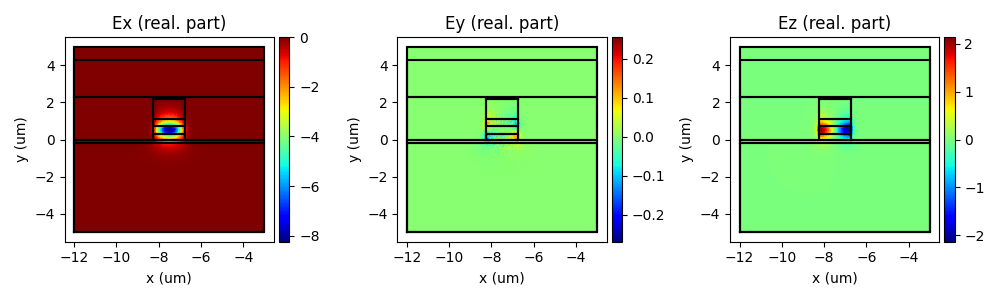

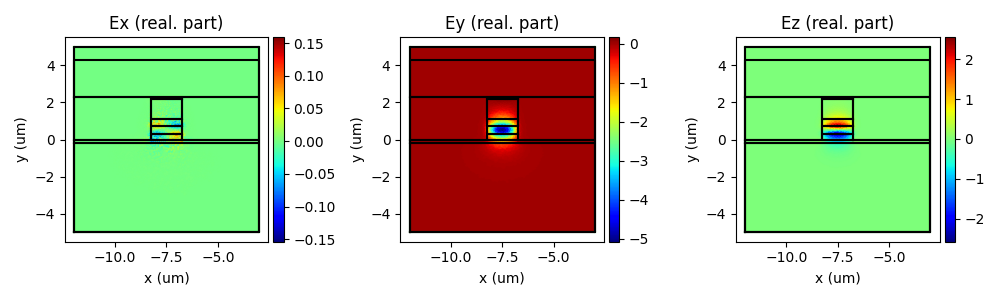

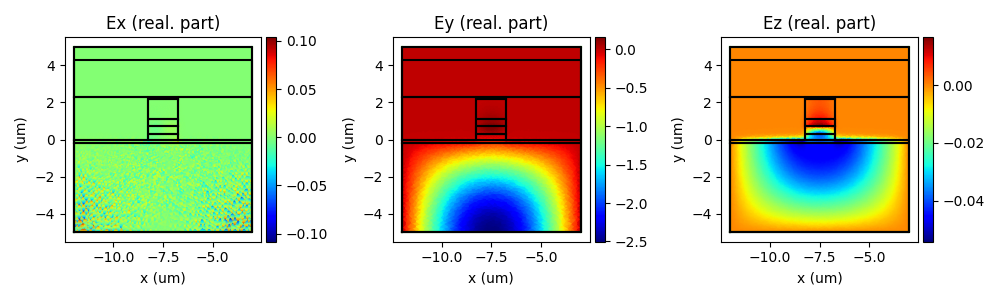

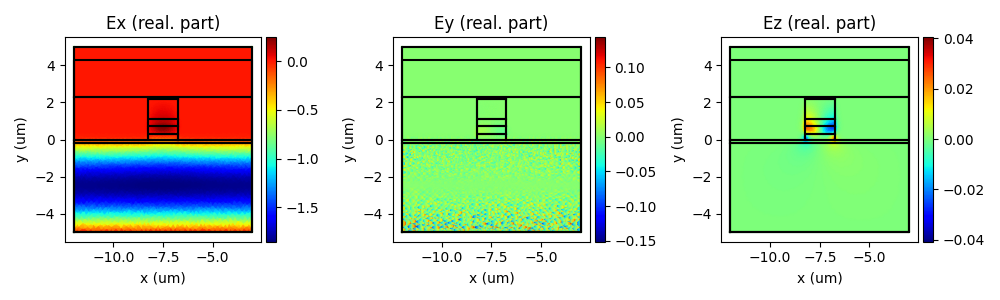

In [20]:
modes = mode.compute_modes(
    wavelength=1.55,
    num_modes=4,
    order=1,
    metallic_boundaries=["top", "bottom", "left", "right"],
    n_guess=3.5,
    return_modes=True
)

for i in range(len(modes)):
    print(f'Effective index - mode {i}: {modes[i].n_eff.real:.4f}')
    print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
    print(f"power: ", modes[i].calculate_power())
    print(f"TE fraction: ", modes[i].te_fraction)
    print(f"TM fraction: ", modes[i].tm_fraction)
    print(f"transversality: {modes[i].transversality}")
    print('#------------------------------------------#')
	
for m in modes:
	mode.plot_mode(m)

In [21]:
mode.transfer_results_to_device(TE_TM_idx = [0,1])

# Compute the poisson-drift-diffusion 

Charge transport will take place with:
L6_right
L5_right
L4_right
L3_right
L2_right
L1


C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Python packages\Imodulator\src\imodulator\ChargeSimulator.py:1907: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure()
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Material "L1" does not have k-data defined. Returning "zeros"
Material "L2_right" does not have k-data defined. Returning "zeros"
Material "L3_right" does not have k-data defined. Returning "zeros"
Material "L4_right" does not have k-data defined. Returning "zeros"
Material "L5_right" does not have k-data defined. Returning "zeros"
Material "L6_right" does not have k-data defined. Returning "zeros"
Solving IV of the junctions...
Solving IV of the tunnel junctions...
Solving IV of the total solar cell...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


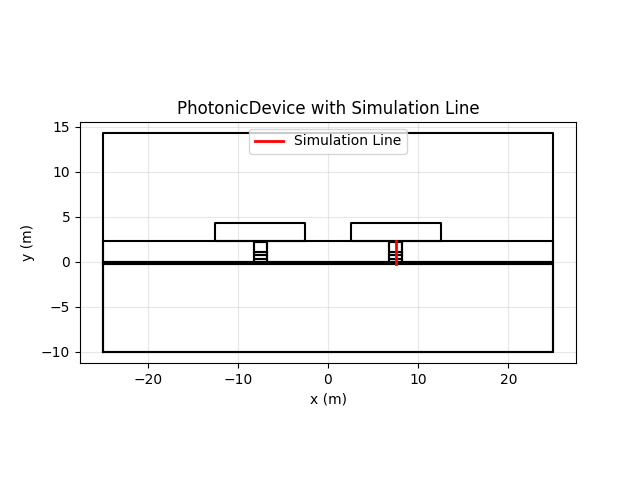

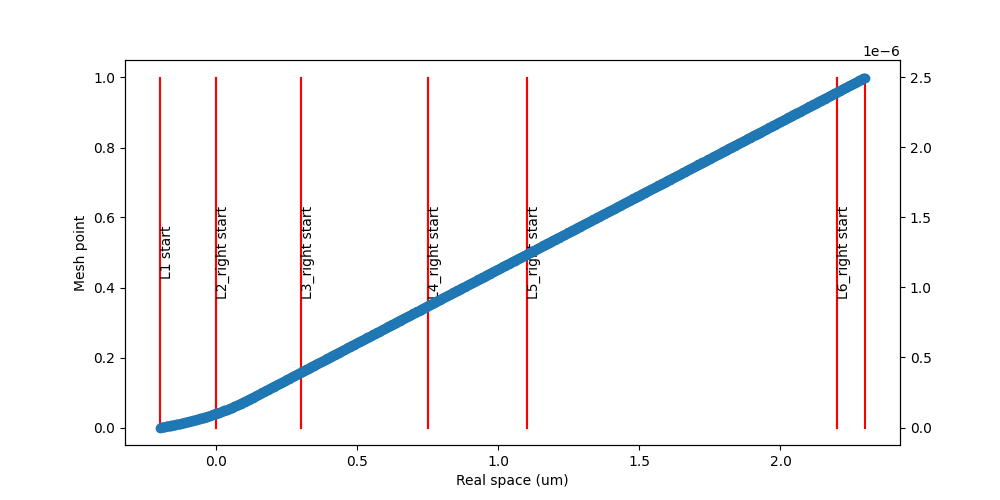

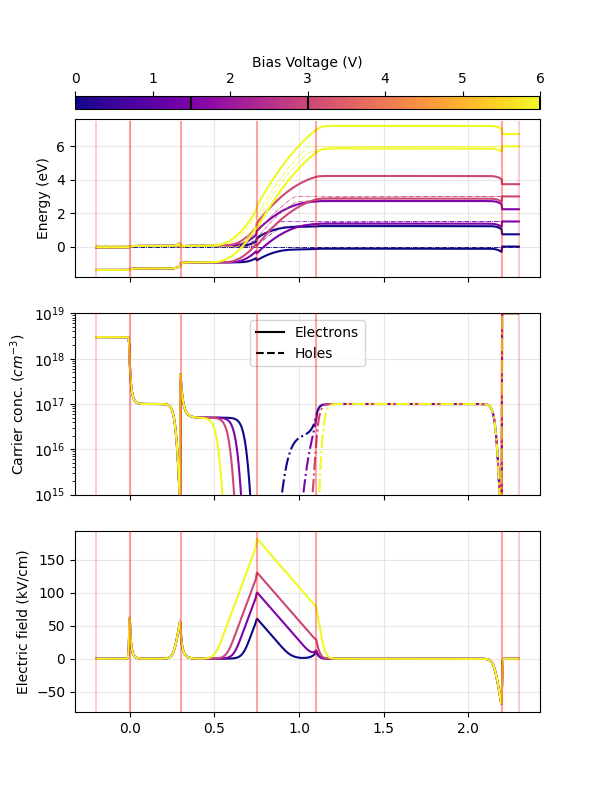

In [22]:
a=shapely.LineString([
    [modulator.metal_sep/2+modulator.w_metal_sig/2,-modulator.h_L1+0.001],
    [modulator.metal_sep/2+modulator.w_metal_sig/2,modulator.h_L2+modulator.h_L3+modulator.h_L4+modulator.h_L5+modulator.h_L6-0.001]])
 
charge=ChargeSimulatorSolcore(
    device=modulator.device,
    simulation_line=a,
    bias_start_stop_step=[0,6,21]
)

fig, ax = charge.plot_with_simulation_line()
charge.plot_mesh()

charge.solve_PDD(
    verbose = True*0,
    tol = 1e-6,
    max_iter = 1000,
    smooth_output=True*0,
    savgol_window = 10
)

charge.plot_results(
    V_idx = [0, 5, 10, 20],
    cmap = 'plasma'
)
charge.transfer_results_to_device(
	dx = 0.1,
	polygons_to_map = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L2_right', 'L3_right', 'L4_right', 'L5_right', 'L6_right'],)

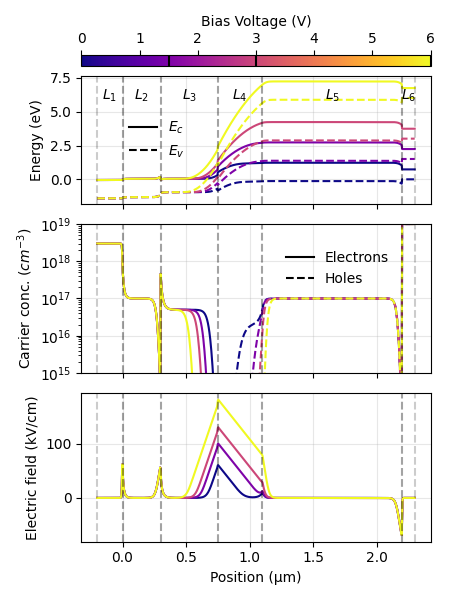

In [29]:
self=charge
cmap = 'plasma'
V_idx = [0, 5, 10, 20]
plot_limits = True
log_scale_carriers = True

cmap = plt.get_cmap(cmap)
norm = plt.Normalize(vmin=min(self.V), vmax=max(self.V))
colors = [cmap(norm(self.V[v])) for v in V_idx]

if V_idx == None:
    V_idx = [0,len(self.V)-1]
    
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(4.5, 6),sharex=True)

ax11 = ax1.twinx() #Ax to plot the vertical lines of the boundaries
ax21 = ax2.twinx() #Ax to plot the vertical lines of the boundaries
ax31 = ax3.twinx() #Ax to plot the vertical lines of the boundaries

ax11.set_axis_off()
ax21.set_axis_off()
ax31.set_axis_off()

for ax in [ax11, ax21, ax31]:
    ax.set_ylim(0,1)
    ax.set_yticks([])

# ax2r = ax2.twinx()
for i, v in enumerate(V_idx):
    ax1.plot(self.mesh, self.Ec[v], "-", color=colors[i])
    ax1.plot(self.mesh, self.Ev[v], "--", color=colors[i])
    # Plot quasi-Fermi levels
    # ax1.plot(self.mesh, self.Efn[v], "--", color=colors[i], linewidth=0.5)
    # ax1.plot(self.mesh, self.Efp[v], "--", color=colors[i], linewidth=0.5)
# Configure first subplot
                
    # ax2 = ax1.twinx()
    ax2.plot(self.mesh,  self.N[v],"-", color=colors[i])
    ax2.plot(self.mesh, self.P[v],"--", color=colors[i])
    
    ax3.plot(self.mesh,self.Efield[v], color = colors[i])
    # ax3.set_ylim(-300,100)

if plot_limits:
    for ax in [ax11, ax21, ax31]:
        for name, segment in self.line_segments.items():
            x0, x1 = segment.xy[0]
            y0, y1 = segment.xy[1]

            ax.plot([y0, y0], [0,1], color = 'black', linestyle='--', label=f'Segment {name}', alpha = 0.2)
            ax.plot([y1, y1], [0,1], color = 'black', linestyle='--', label=f'Segment {name}', alpha = 0.2)

labels = ['$L_1$', '$L_2$', '$L_3$', '$L_4$', '$L_5$', '$L_6$']
for label, name, segment in zip(labels, self.line_segments.keys(), self.line_segments.values()):
    x0, x1 = segment.xy[0]
    y0, y1 = segment.xy[1]

    ax11.text((y0 + y1) / 2, 0.85, f'{label}', ha='center', va='center')


ax1.plot([],[],color='black', linestyle='-', label = '$E_c$')
ax1.plot([],[],color='black', linestyle='--', label = '$E_v$')
ax1.set_ylabel('Energy (eV)')
ax1.grid(True, alpha=0.3)
leg = ax1.legend(loc='center left', frameon=False, bbox_to_anchor=(0.1,0.5))

ax2.set_ylabel(r"Carrier conc. ($cm^{-3}$)")
ax2.grid(True, alpha=0.3)
# ax2.legend(loc='best')
if log_scale_carriers:
    ax2.set_yscale('log')
ax2.set_ylim(1e15,1e19)

#Add dummy lines so that we can put a legend for electron and hole
l1, = ax2.plot([],[], 'k-', label='Electrons')
l2, = ax2.plot([],[], 'k--', label='Holes')
ax2.legend(handles=[l1,l2], loc='center left', frameon=False, bbox_to_anchor=(0.55,0.7))

ax3.set_ylabel(r"Electric field (kV/cm)")
ax3.set_xlabel('Position (μm)')

ax3.grid(True, alpha=0.3)
# ax3.legend(loc='best')

from mpl_toolkits.axes_grid1 import make_axes_locatable

norm_cbar = plt.Normalize(vmin=self.V[min(V_idx)], vmax=self.V[max(V_idx)])

divider = make_axes_locatable(ax1)
cax = divider.append_axes('top', size='8%', pad=0.1)

ax11.set_ylim(0,1.17) #A small compensation so that the lines are nice



sm = plt.cm.ScalarMappable(norm=norm_cbar, cmap=cmap)
sm.set_array([])  # required in older mpl versions

cb = fig.colorbar(sm, cax=cax, orientation='horizontal')
cb.ax.xaxis.set_ticks_position('top')
cb.ax.xaxis.set_label_position('top')

cb.set_label('Bias Voltage (V)')

for v in [self.V[vi] for vi in V_idx]:
    cb.ax.axvline(v, color='k', lw=1.5)

fig.tight_layout()
fig.savefig("../Images/Charge_simulation_results.png", dpi=300)

# Calculate electro-optical response

The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


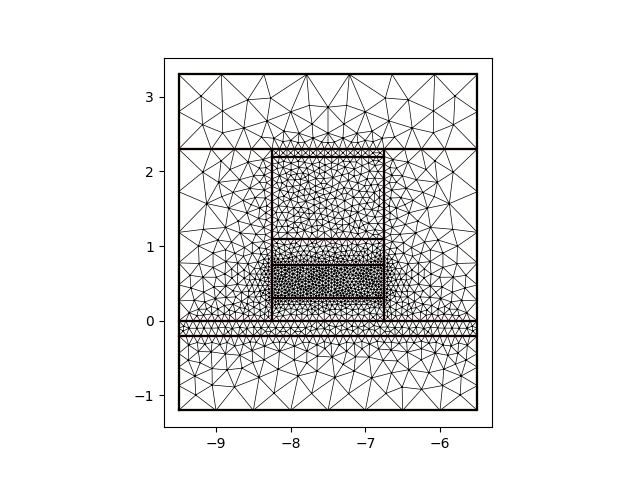

In [30]:
EO=ElectroOpticalSimulator(
    device=modulator.device,
    simulation_window=shapely.box(
        -modulator.w_metal_sig/2-modulator.metal_sep/2-2,
        -modulator.h_L1-1,
        -modulator.w_metal_sig/2-modulator.metal_sep/2+2,
        modulator.h_L2+modulator.h_L3+modulator.h_L4+modulator.h_L5+modulator.h_L6+1
    ),
	wavelength=1550
)

EO.make_mesh()
fig, ax = EO.plot_mesh()
EO.plot_polygons(ax=ax)

(100, 100, 3)


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\matplotlib\cbook.py:733: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\matplotlib\cbook.py:733: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  x = np.array(x, subok=True, copy=copy)


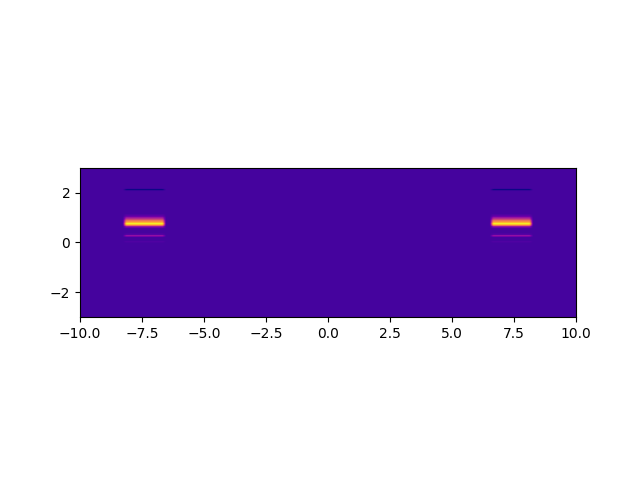

In [31]:
x = np.linspace(-10,10,100)
y = np.linspace(-3,3,100)

xx,yy = np.meshgrid(x,y)

Efield = modulator.device.charge['Efield'][5](xx,yy)
print(Efield.shape)
plt.figure()
plt.imshow(Efield[:,:,1], extent=[x.min(), x.max(), y.min(), y.max()], origin='lower', cmap='plasma')

In [32]:
EO.get_epsilon_optical()

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: divide by zero encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facet

In [34]:
#Calculate the EO response for all voltages
angle_values = np.linspace(-np.pi/2, np.pi/2, 65)

kappa_te_te = np.zeros((len(angle_values), len(modulator.device.charge['V']), 5), dtype=complex)
kappa_te_tm = np.zeros((len(angle_values), len(modulator.device.charge['V']), 5), dtype=complex)
kappa_tm_te = np.zeros((len(angle_values), len(modulator.device.charge['V']), 5), dtype=complex)
kappa_tm_tm = np.zeros((len(angle_values), len(modulator.device.charge['V']), 5), dtype=complex)

manager = enlighten.get_manager()
pbar = manager.counter(total=len(angle_values), desc='Calculating EO response', unit='angles')
pbar2 = manager.counter(total=len(modulator.device.charge['V']), desc='Voltages', unit='steps')

for j in range(len(angle_values)):
    pbar2.count=0
    for i in range(len(modulator.device.charge['V'])):

        for mode_a, mode_b, storage_list in zip(
            ['TE', 'TE', 'TM', 'TM'],
            ['TE', 'TM', 'TE', 'TM'],
            [kappa_te_te, kappa_te_tm, kappa_tm_te, kappa_tm_tm]
        ):
            kappa = EO.calculate_EO_response(
                voltage_idx=i,
                rot_x=0,
                rot_y=angle_values[j],
                rot_z=0,
                base_epsilon_voltage_idx=0,
                optical_mode_a=mode_a,
                optical_mode_b=mode_b,
            )
            storage_list[j,i] = kappa['InGaAsPElectroOpticalModel']['results']
        pbar2.update()
    pbar.update()

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


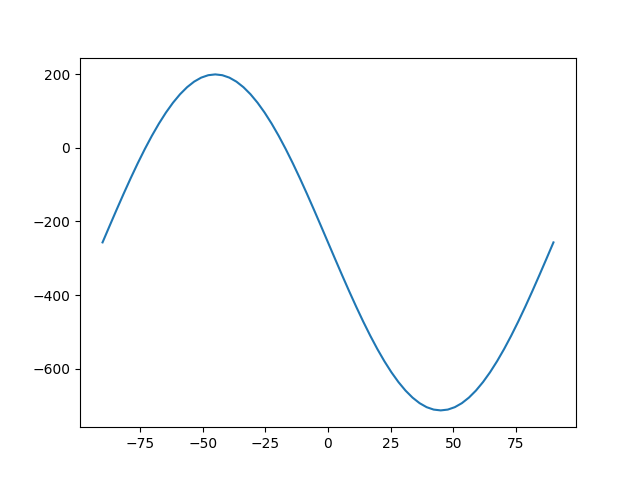

In [35]:
beta_TE = modes[1].k
beta_TM = modes[0].k
dbeta = beta_TM - beta_TE

plt.figure()
plt.plot(angle_values/np.pi*180, (dbeta + np.sum(kappa_tm_tm[:,-1], axis=-1)-np.sum(kappa_te_te[:,-1], axis=-1)), label='Re(Δβ)')

The plot above tells us about the effective phase mismatch between the two modes.

In [36]:
print(angle_values[16]/np.pi)
print(angle_values[48]/np.pi)

-0.25
0.25


In [37]:
from scipy.integrate import solve_ivp

def f1(z,y, kaa=1, kbb=1, kba=0, kab=0, beta_TE=1, beta_TM=1):
    """
    This is the coupled mode equations for the TE and TM modes in the presence of coupling.
    """
    A=y[0]
    B=y[1]

    dAdz=1j*kaa*A+1j*kab*B*np.exp(1j*(beta_TM-beta_TE)*z)
    dBdz=1j*kbb*B+1j*kba*A*np.exp(-1j*(beta_TM-beta_TE)*z)

    return np.array([dAdz, dBdz])

z_space = np.linspace(0, 50e-3, 100)
A_values = np.zeros((len(angle_values), len(z_space)), dtype=complex)
B_values = np.zeros((len(angle_values), len(z_space)), dtype=complex)

manager = enlighten.get_manager()
pbar = manager.counter(total=len(angle_values), desc='Simulating propagation', unit='angles')

for j in range(len(angle_values)):
    
    voltage_idx = -1

    k_aa = np.sum(kappa_te_te[j,voltage_idx], axis = -1)
    k_ab = np.sum(kappa_te_tm[j,voltage_idx], axis = -1)
    k_ba = np.sum(kappa_tm_te[j,voltage_idx], axis = -1)
    k_bb = np.sum(kappa_tm_tm[j,voltage_idx], axis = -1)
    # idx_ef = [0,1,2,3]
    # k_aa = np.sum(kappa_te_te[j,voltage_idx, idx_ef], axis=-1).real*0
    # k_ab = np.sum(kappa_te_tm[j,voltage_idx, idx_ef], axis=-1).real
    # k_ba = np.sum(kappa_tm_te[j,voltage_idx, idx_ef], axis=-1).real
    # k_bb = np.sum(kappa_tm_tm[j,voltage_idx, idx_ef], axis=-1).real*0

    beta_TE = mode.modes[1].k
    beta_TM = mode.modes[0].k


    result = solve_ivp(
        fun=lambda z, y: f1(z, y, kaa=k_aa, kbb=k_bb, kba=k_ba, kab=k_ab, beta_TE=beta_TE, beta_TM=beta_TM),
        t_span=(0, z_space[-1]),
        y0=np.array([1+0j, 0+0j]),
        t_eval=z_space,
        rtol = 1e-12,
        atol = 1e-12
    )

    A_values[j,:] = result.y[0]
    B_values[j,:] = result.y[1]
    pbar.update()

<>:123: DeprecationWarning: invalid escape sequence '\p'
<>:123: DeprecationWarning: invalid escape sequence '\p'
C:\Users\20230622\AppData\Local\Temp\ipykernel_12464\4088113157.py:123: DeprecationWarning: invalid escape sequence '\p'
  ax_pol.set_ylabel('$\phi$ ($^{\circ}$)')


['Bandfilling', 'Plasma + intraband + interband', 'Intervalence', 'Pockels', 'Kerr']
Selected angle: 45.00 degrees
Selected angle (polarization): -16.87 degrees


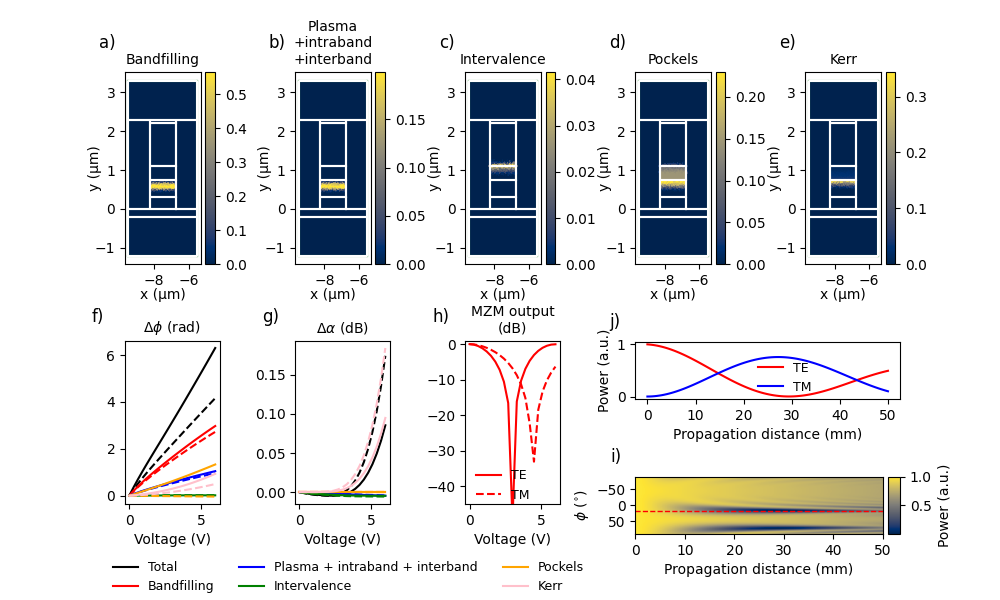

In [47]:
eo_labels = EO.epsilon_optical['InGaAsPElectroOpticalModel']['labels']
eo_dperms = EO.epsilon_optical['InGaAsPElectroOpticalModel']['dperms']


eo_labels[1] = 'Plasma + intraband + interband'

print(eo_labels)

voltage_idx = -1
angle_idx = 16+32 #48
angle_idx_pol = 32-6
print(f"Selected angle: {angle_values[angle_idx]/np.pi*180:.2f} degrees")
print(f"Selected angle (polarization): {angle_values[angle_idx_pol]/np.pi*180:.2f} degrees")
fig = plt.figure(figsize = (10,6))
gs = fig.add_gridspec(
    4, 5,
    hspace = 1.35,
    wspace = 0.8
    )

ax_bf = fig.add_subplot(gs[0:2, 0])
ax_plasma = fig.add_subplot(gs[0:2, 1])
ax_iv = fig.add_subplot(gs[0:2, 2])
ax_pockels = fig.add_subplot(gs[0:2, 3])
ax_kerr = fig.add_subplot(gs[0:2, 4])
ax_dbeta_re = fig.add_subplot(gs[2:4, 0])
ax_dbeta_im = fig.add_subplot(gs[2:4, 1])
ax_mzm = fig.add_subplot(gs[2:4, 2])
ax_pol = fig.add_subplot(gs[3, 3:])
ax_pol_single = fig.add_subplot(gs[2, 3:])


tensor_idxs = [(0,0), (0,0), (0,0), (0,2), (0,0)]
for idx, label, ax, tensor_idx in zip(range(len(eo_labels)), eo_labels, [ax_bf, ax_plasma, ax_iv, ax_pockels, ax_kerr], tensor_idxs):
    im = EO.basis.plot(
        (eo_dperms[tensor_idx[0], tensor_idx[1], :, voltage_idx, idx] - 
         eo_dperms[tensor_idx[0], tensor_idx[1], :, 0, idx]
        ).real*100, ax = ax, cmap = 'cividis', colorbar=True)
    EO.plot_polygons(fig = fig, ax = ax, color_polygon = 'white')
    if idx ==1:
        label = 'Plasma\n+intraband\n+interband'

    ax.set_title(f"{label}", fontsize=10)
    ax.set_xlabel('x (μm)', fontsize=10, labelpad=0)
    ax.set_ylabel('y (μm)', fontsize=10, labelpad=-5)

colors = ['black', 'red', 'blue', 'green', 'orange', 'pink']
device_length = 3e-3
ax_dbeta_re.plot(
    modulator.device.charge['V'],
    np.sum(kappa_te_te[angle_idx]*device_length, axis=1).real,
    color = colors[0],
    label = 'Total'
)

ax_dbeta_re.plot(
    modulator.device.charge['V'],
    np.sum(kappa_tm_tm[angle_idx]*device_length, axis=1).real,
    color = colors[0],
    linestyle = 'dashed',
)

for i in range(5):
    ax_dbeta_re.plot(
        modulator.device.charge['V'],
        kappa_te_te[angle_idx,:,i].real*device_length,
        color = colors[i+1],
        label = f"{eo_labels[i]}"
    )

    ax_dbeta_re.plot(
        modulator.device.charge['V'],
        kappa_tm_tm[angle_idx,:,i].real*device_length,
        color = colors[i+1],
        linestyle = 'dashed',
        # label = f"{eo_labels[i]} (TM)"
    )

ax_dbeta_im.plot(
    modulator.device.charge['V'],
    4.343*2*np.sum(kappa_te_te[angle_idx]*device_length, axis=1).imag,
    color = colors[0],
)

ax_dbeta_im.plot(
    modulator.device.charge['V'],
    4.343*2*np.sum(kappa_tm_tm[angle_idx]*device_length, axis=1).imag,
    color = colors[0],
    linestyle = 'dashed'
)

for i in range(5):
    ax_dbeta_im.plot(
        modulator.device.charge['V'],
        4.343*2*kappa_te_te[angle_idx,:,i].imag*device_length,
        color = colors[i+1],
        label = f"{eo_labels[i]}"
    )

    ax_dbeta_im.plot(
        modulator.device.charge['V'],
        4.343*2*kappa_tm_tm[angle_idx,:,i].imag*device_length,
        color = colors[i+1],
        linestyle = 'dashed',
        # label = f"{eo_labels[i]} (TM)"
    )

MZM_output_TE = 10*np.log10(np.abs(1/2 * (1 + np.exp(1j*np.sum(kappa_te_te[angle_idx]*device_length, axis=1))))**2)
MZM_output_TM = 10*np.log10(np.abs(1/2 * (1 + np.exp(1j*np.sum(kappa_tm_tm[angle_idx]*device_length, axis=1))))**2)

ax_mzm.plot(modulator.device.charge['V'], MZM_output_TE, color = colors[1], label = 'TE')
ax_mzm.plot(modulator.device.charge['V'], MZM_output_TM, color = colors[1], linestyle = 'dashed', label = 'TM')

im = ax_pol.imshow(
    np.abs(A_values)**2,
    extent=[z_space.min()*1e3, z_space.max()*1e3, angle_values.max()/np.pi*180, angle_values.min()/np.pi*180],
    origin='lower',
    aspect='auto',
    cmap='cividis'
)
ax_pol.axhline(-angle_values[angle_idx_pol]/np.pi*180, color = 'red', linestyle = '--', linewidth=1)
ax_pol.set_xlabel('Propagation distance (mm)')
ax_pol.set_ylabel('$\phi$ ($^{\circ}$)')
divider = make_axes_locatable(ax_pol)
cax = divider.append_axes('right', size='5%', pad=0.05)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Power (a.u.)')

ax_pol_single.plot(z_space*1e3, np.abs(A_values[angle_idx_pol])**2, color = colors[1], label = 'TE')
ax_pol_single.plot(z_space*1e3, np.abs(B_values[angle_idx_pol])**2, color = colors[2], label = 'TM')
ax_pol_single.legend(frameon=False, loc='upper left', fontsize=9, bbox_to_anchor=(0.42, 0.85))
ax_pol_single.set_xlabel('Propagation distance (mm)')
ax_pol_single.set_ylabel('Power (a.u.)')

for ax in [ax_dbeta_re, ax_dbeta_im, ax_mzm]:
    pos = ax.get_position()
    ax.set_position([
        pos.x0,
        pos.y0 + 0.05,      # move upward
        pos.width,
        pos.height * 0.85   # shrink height
    ])

ax_dbeta_re.set_xlabel('Voltage (V)')
ax_dbeta_re.set_title(r'$\Delta \phi$ (rad)', fontsize=10)
ax_dbeta_re.legend(frameon=False, loc='upper left', bbox_to_anchor=(-0.25, -0.28), fontsize=9, ncol = 3)

ax_dbeta_im.set_xlabel('Voltage (V)')
ax_dbeta_im.set_title(r'$\Delta \alpha$ (dB)', fontsize=10)

ax_mzm.set_xlabel('Voltage (V)')
ax_mzm.set_title('MZM output\n(dB)', fontsize=10)
ax_mzm.legend(frameon=False, loc='upper left', bbox_to_anchor=(0., 0.28), fontsize=9, ncol = 1)
ax_mzm.set_ylim(-45,1)


#Place labels on the plots
labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)', 'i)', 'j)']
for ax, label in zip([ax_bf, ax_plasma, ax_iv, ax_pockels, ax_kerr, ax_dbeta_re, ax_dbeta_im, ax_mzm, ax_pol, ax_pol_single], labels):
    x = -0.35
    y = 1.2

    if ax in [ax_pol, ax_pol_single]:
        x = -0.1
        y = 1.5

    ax.text(x, y, label, transform=ax.transAxes, fontsize=12, va='top')
# fig.tight_layout()
fig.savefig("../Images/EO_calculations.png", dpi=300)

The assymetric behaviour stems from the diagonal elements of the coupling tensor \kappa. Essentially we are including an additional phase mismatch

# Calculate RF response

In [48]:
from scipy.interpolate import CubicSpline

def extend_array(
        x,y, N=100
):

    f_interp = lambda t: CubicSpline(x,y.real, axis = 1)(t)  + 1j*CubicSpline(x,y.imag, axis =1)(t)
    
    x_new = np.linspace(np.min(x), np.max(x), N)
    y_new = f_interp(x_new)

    return y_new

def get_EO(
    freq,
    neff,
    loss,
    Z,
    L,
    ZS = 50,
    ZL = 50,
    N_new_freq = 100  ,
    no = 3.25
):
    
    loss_new = extend_array(freq, loss, N_new_freq)
    neff_new = extend_array(freq, neff, N_new_freq)
    Z_new = extend_array(freq, Z, N_new_freq)
    freq_new =  np.linspace(np.min(freq), np.max(freq), N_new_freq)
    
    alpha = loss_new*100 * np.log(10) / 20  # convert to Np/m
    beta = 2 * np.pi * freq_new * 1e9 * neff_new / 3e8  # in rad/m
    k = alpha + 1j * beta

    R_L = np.real(ZL)
    R_S = np.real(ZS)

    c_0 = 3e8  # speed of light in vacuum
    R_L = R_L
    R_G = R_S
    Z_0 = Z_new
    Z_L = ZL
    Z_G = ZS

    Z_in = Z_0 * (Z_L + Z_0 * np.tanh(k*L)) / (Z_0 + Z_L * np.tanh(k*L)) #RF line input impedance 
    w= freq_new*2*np.pi*1e9
    u_p = (alpha*L) + (1j* w)*(neff_new-no)*L /(c_0)
    u_m = -(alpha*L) + (1j* w)*(-neff_new-no)*L /(c_0)
    fu_p = (1 - np.exp(u_p)) / u_p
    fu_m = (1 - np.exp(u_m)) / u_m
    mw = (
        ((R_L + R_G) / R_L)
        * np.absolute(Z_in / (Z_in + Z_G))
        * np.absolute(
            (((Z_L + Z_0) * fu_p) + ((Z_L - Z_0) * fu_m))
            / (
                ((Z_L + Z_0) * np.exp(k * L))
                + ((Z_L - Z_0) * np.exp(-k * L))
            )
        )
    )
    return 20*np.log10(mw) #The factor of 20log10 is because we want to consider the EO bandwidth as the power of an electrical signal generated by the optical power, like the current of a perfect photodiode.

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(
C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Python packages\Imodulator\src\imodulator\RFSimulator.py:526: RuntimeWarning: divide by zero encountered in log10
  data_to_plot_im = np.log10(-data_to_plot_im)


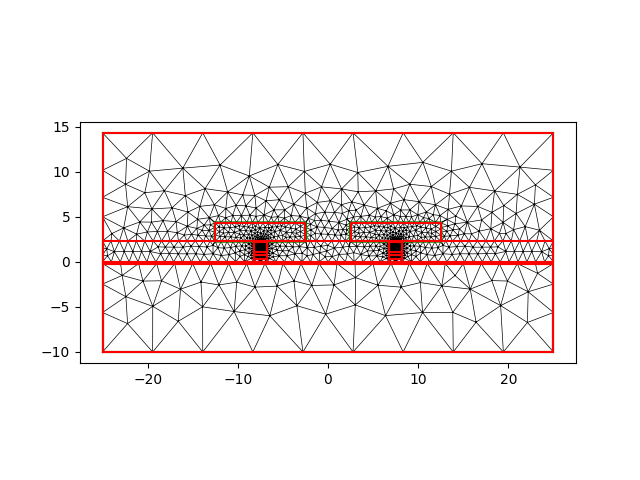

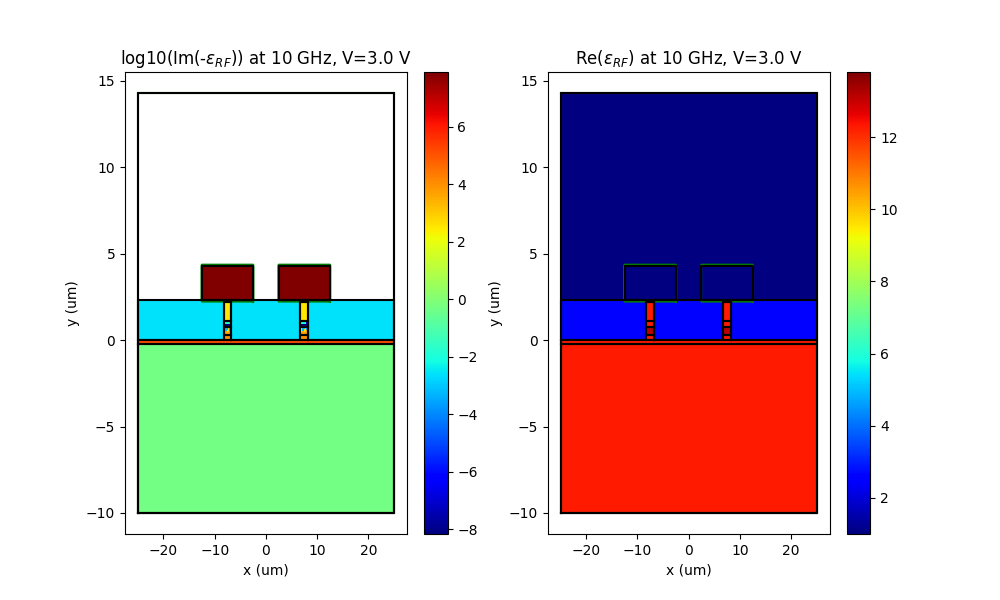

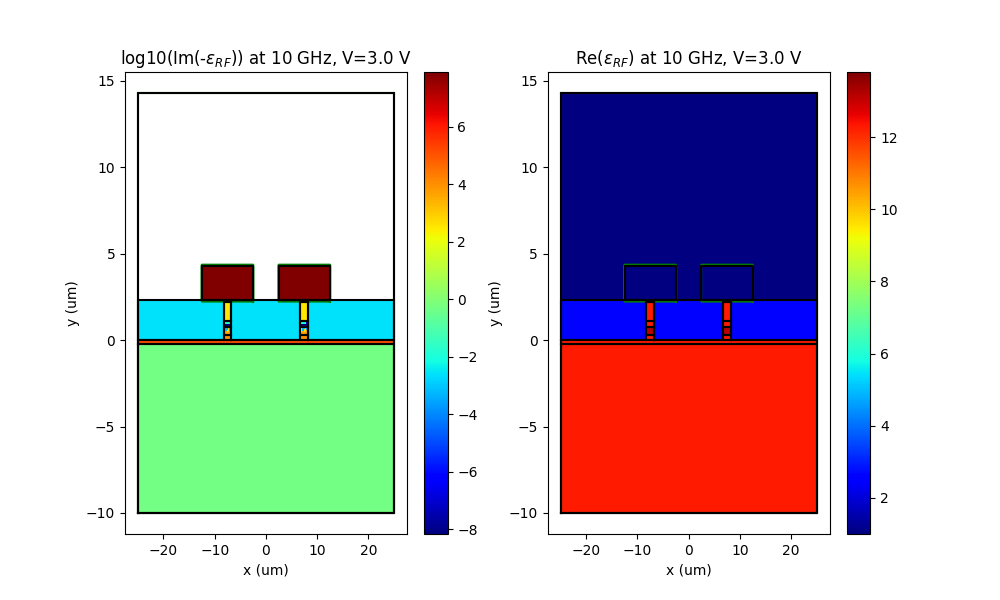

In [49]:
rf_sim = RFSimulator(modulator.device, simulation_window=shapely.box(-75, -50, 75, 50))
rf_sim.make_mesh(
                gmsh_algorithm=1,
                verbose=True
            )

rf_sim.plot_mesh()
_ = rf_sim.plot_eps_rf(
    frequency=10, #GHz
    log_scale_re=False,
    log_scale_im=True,
    use_charge_transport_data=True,
    voltage_idx=10
)

fig, ax1, ax2 = rf_sim.plot_eps_rf(
    frequency=10, #GHz
    log_scale_re=False,
    log_scale_im=True,
    use_charge_transport_data=True,
    voltage_idx=10
)

In [50]:
## mesh refinement
rf_sim = RFSimulator(modulator.device, simulation_window=shapely.box(-75, -50, 75, 50))
rf_sim.make_mesh(
                gmsh_algorithm=1,
                verbose=True
            )

freq_refinement = 40 #GHz, we want to optimize for the EO response at this frequency
N_mesh_refinement = 20 # Maximum number of mesh refinement steps
N_elements_max = 12_000 #Maximum number of mesh elements. Refinement stops when either N_mesh refinement steps are reached or the number of mesh elements exceeds N_elements_max
n_modes = 1 #We only want the fundamental mode for the RF simulation

n_elements_refinement = np.zeros(N_mesh_refinement)
neff_values_refinement = np.zeros(N_mesh_refinement)
loss_values_refinement = np.zeros(N_mesh_refinement)
Z0_values_refinement = np.zeros(N_mesh_refinement, dtype=complex)

boundary_conditions = ['left', 'bottom','top','right']

for i in range(N_mesh_refinement):
                        
    #Compute modes
    modes2 = rf_sim.compute_modes(
        frequency = freq_refinement,
        metallic_boundaries = boundary_conditions,
        n_guess = 3,
        num_modes = n_modes,
        order = 1,
        return_modes = True,
        use_charge_transport_data=True,
        voltage_idx=int(len(modulator.device.charge['V'])/2)
    )

    idx_mode=0

    ######### Calculate characteristic impedance #########
    p0, i0_all, _ = rf_sim.get_currents(mode = rf_sim.modes[idx_mode])
    # print(i0_all)

    I0 = i0_all['sig_metal_line_current'] #<--- This is crucial!

    # p0 = 2*p0 
    Z0 = p0/np.abs(I0)**2

    rf_sim.refine_mesh(
        mode_for_refinement=rf_sim.modes[idx_mode], 
        N_nearest_neighbours=500
    )

    neff_values_refinement[i] = rf_sim.modes[idx_mode].n_eff.real
    loss_values_refinement[i] = rf_sim.modes[idx_mode].calculate_propagation_loss(1e4)
    Z0_values_refinement[i] = Z0
    n_elements_refinement[i] = rf_sim.mesh.nelements

    if rf_sim.mesh.nelements > N_elements_max:
        print("Reached maximum number of elements. Stopping refinement.")
        break

    print(f"Refinement step {i+1}/{N_mesh_refinement}: n_elements = {rf_sim.mesh.nelements}, n_eff = {neff_values_refinement[i]:.4f}, loss = {loss_values_refinement[i]:.2f} dB/cm, Z0 = {Z0_values_refinement[i]:.2f} Ohm")

neff_values_refinement = neff_values_refinement[:i+1]
loss_values_refinement = loss_values_refinement[:i+1]
Z0_values_refinement = Z0_values_refinement[:i+1]
n_elements_refinement = n_elements_refinement[:i+1]

Refinement step 1/20: n_elements = 2574, n_eff = 3.1643, loss = 52.86 dB/cm, Z0 = 61.86+9.67j Ohm
Refinement step 2/20: n_elements = 2783, n_eff = 3.0950, loss = 40.43 dB/cm, Z0 = 60.45+6.43j Ohm
Refinement step 3/20: n_elements = 3643, n_eff = 3.1011, loss = 40.48 dB/cm, Z0 = 60.65+6.45j Ohm
Refinement step 4/20: n_elements = 4704, n_eff = 3.0956, loss = 40.61 dB/cm, Z0 = 57.32+6.11j Ohm
Refinement step 5/20: n_elements = 6456, n_eff = 3.0896, loss = 41.02 dB/cm, Z0 = 54.99+5.98j Ohm
Refinement step 6/20: n_elements = 7322, n_eff = 3.0804, loss = 41.58 dB/cm, Z0 = 54.18+6.06j Ohm
Refinement step 7/20: n_elements = 9605, n_eff = 3.0766, loss = 41.33 dB/cm, Z0 = 53.12+5.89j Ohm
Reached maximum number of elements. Stopping refinement.


In [51]:
#Compute modes
modes = rf_sim.compute_modes(
    frequency = freq_refinement,
    metallic_boundaries = ['left', 'bottom','top', 'right'],
    n_guess = 3,
    num_modes = 2,
    order = 1,
    return_modes = True,
    use_charge_transport_data=True,
    voltage_idx=int(len(modulator.device.charge['V'])/2)
)

In [52]:
rf_sim_old = RFSimulator(modulator.device, simulation_window=shapely.box(-75, -50, 75, 50))
rf_sim_old.make_mesh(
                gmsh_algorithm=1,
                verbose=True
            )

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


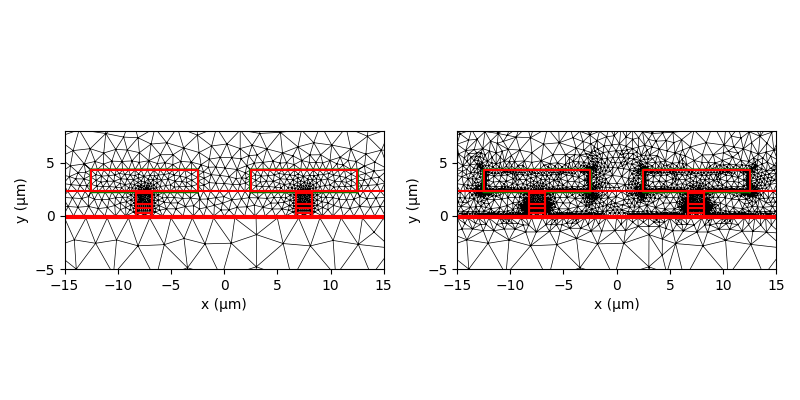

In [53]:
fig = plt.figure(figsize=(8,4))
gs = fig.add_gridspec(1, 2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

rf_sim_old.plot_mesh(ax=ax1)
rf_sim.plot_mesh(ax=ax2)

for ax in [ax1, ax2]:
    ax.set_xlabel('x (μm)')
    ax.set_ylabel('y (μm)')
    ax.set_xlim(-15, 15)
    ax.set_ylim(-5, 8)
    ax.set_aspect('equal')

fig.tight_layout()

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


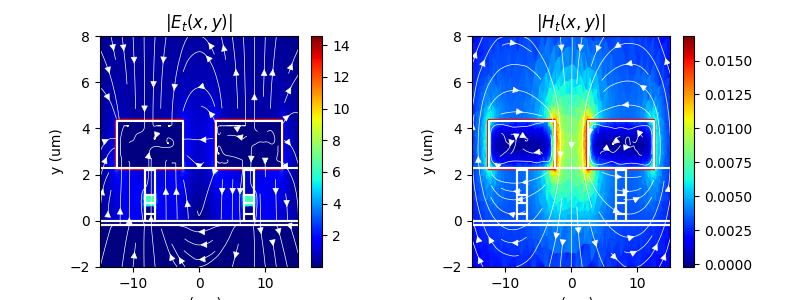

In [54]:
rf_sim.plot_mode(
	modes[0],
	xmin = -15, xmax = 15, ymin = -2, ymax = 8, plot_vectors=True,
	figsize=(8,3),
	cmap = 'jet',
	color_vectors = 'white',
	vector_density = 0.65
)

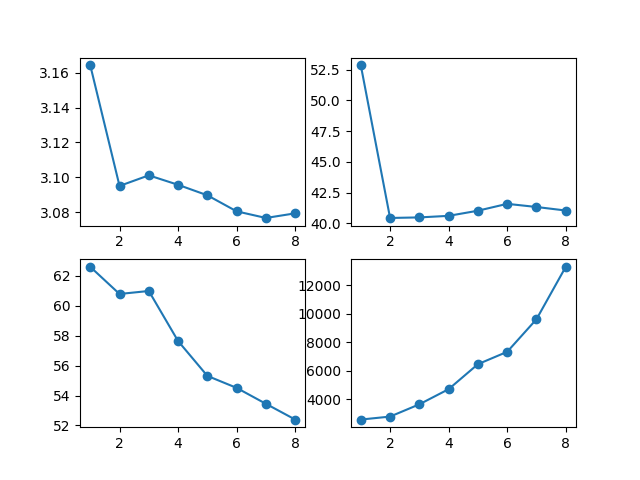

In [55]:
fig = plt.figure()
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])


n_iterations = np.arange(1, len(neff_values_refinement)+1)

ax1.plot(n_iterations, neff_values_refinement, marker='o')
ax2.plot(n_iterations, loss_values_refinement, marker='o')
ax3.plot(n_iterations, np.abs(Z0_values_refinement), marker='o')
ax4.plot(n_iterations, n_elements_refinement, marker='o')

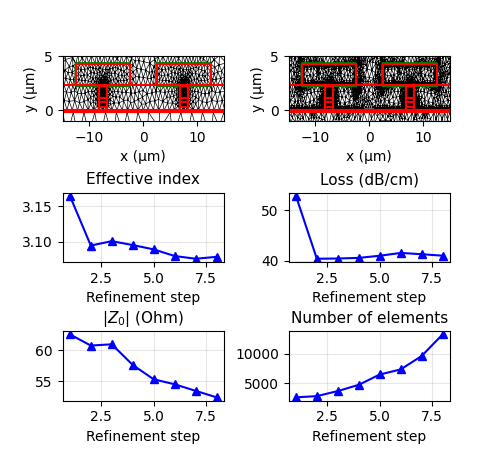

In [56]:
fig = plt.figure(figsize=(5,4.5))
gs = fig.add_gridspec(
    3, 
    2, 
    wspace = 0.4, 
    hspace = 1, 
    height_ratios=[1,1,1]
    )

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

# ax3 = fig.add_subplot(gs[1, 0])
# ax4 = fig.add_subplot(gs[1, 1])

ax5 = fig.add_subplot(gs[1, 0])
ax6 = fig.add_subplot(gs[1, 1])

ax7 = fig.add_subplot(gs[2, 0])
ax8 = fig.add_subplot(gs[2, 1])

rf_sim_old.plot_mesh(ax=ax1)
rf_sim.plot_mesh(ax=ax2)

for ax in [ax1, ax2]:
    ax.set_xlabel('x (μm)')
    ax.set_ylabel('y (μm)')
    ax.set_xlim(-15, 15)
    ax.set_ylim(-1, 5)
    ax.set_aspect(2)

# rf_sim.plot_mode(
#     modes[0],
#     xmin = -15, xmax = 15, ymin = -2, ymax = 8, plot_vectors=True,
#     cmap = 'jet',
#     color_polygons = (1,1,1,0.3),
#     color_vectors = 'white',
#     vector_density = 0.65,
#     axes=[ax3, ax4]
# )
n_iterations = np.arange(1, len(neff_values_refinement)+1)
ax5.plot(n_iterations, neff_values_refinement, marker='^', color = 'blue')
ax6.plot(n_iterations, loss_values_refinement, marker='^', color = 'blue')
ax7.plot(n_iterations, np.abs(Z0_values_refinement), marker='^', color = 'blue')
ax8.plot(n_iterations, n_elements_refinement, marker='^', color = 'blue')

ax5.set_title('Effective index', fontsize=11)
ax6.set_title('Loss (dB/cm)', fontsize=11)
ax7.set_title('$|Z_0|$ (Ohm)', fontsize=11)
ax8.set_title('Number of elements', fontsize=11)

for ax in [ax5, ax6, ax7, ax8]:
    ax.set_xlabel('Refinement step')
    ax.grid(True, alpha=0.3)

# ax3.set_title("")
# ax4.set_title("")
# ax3.set_aspect(1)
# ax4.set_aspect(2)
# ax3.set_title('$E_t$', fontsize=11)
# ax4.set_title('$H_t$', fontsize=11)

# for ax in [ax3, ax4]:
#     ax.set_ylim(-5,8)

fig.savefig("../Images/RF_refinement_results.png", dpi=300)
# fig.tight_layout()

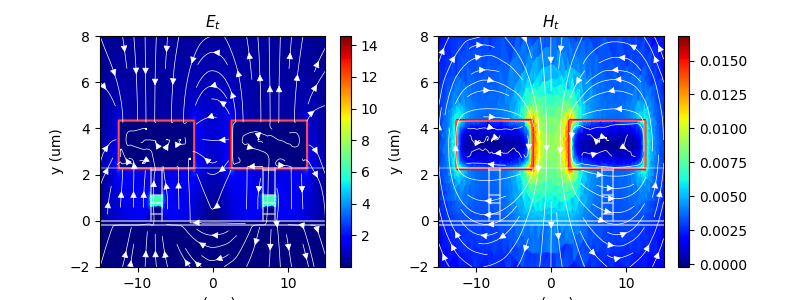

In [57]:
fig = plt.figure(figsize=(8,3))
gs = fig.add_gridspec(1, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

rf_sim.plot_mode(
    modes[0],
    xmin = -15, xmax = 15, ymin = -2, ymax = 8, plot_vectors=True,
	Nx=100, Ny=100,
    cmap = 'jet',
    color_polygons = (1,1,1,0.3),
    color_vectors = 'white',
    vector_density = 0.7,
    axes=[ax1, ax2]
)

ax1.set_title('$E_t$', fontsize=11)
ax2.set_title('$H_t$', fontsize=11)

fig.savefig("../Images/RF_mode_fields.png", dpi=300)

In [58]:
## mesh refinement
rf_sim = RFSimulator(modulator.device, simulation_window=shapely.box(-75, -50, 0, 50))
rf_sim.make_mesh(
                gmsh_algorithm=1,
                verbose=True
            )

freq_refinement = 40 #GHz, we want to optimize for the EO response at this frequency
N_mesh_refinement = 20 # Maximum number of mesh refinement steps
N_elements_max = 12_000 #Maximum number of mesh elements. Refinement stops when either N_mesh refinement steps are reached or the number of mesh elements exceeds N_elements_max
n_modes = 1 #We only want the fundamental mode for the RF simulation

n_elements_refinement = np.zeros(N_mesh_refinement)
neff_values_refinement = np.zeros(N_mesh_refinement)
loss_values_refinement = np.zeros(N_mesh_refinement)
Z0_values_refinement = np.zeros(N_mesh_refinement, dtype=complex)

boundary_conditions = ['left', 'bottom','top','right']

for i in range(N_mesh_refinement):
                        
    #Compute modes
    modes2 = rf_sim.compute_modes(
        frequency = freq_refinement,
        metallic_boundaries = boundary_conditions,
        n_guess = 3,
        num_modes = n_modes,
        order = 1,
        return_modes = True,
        use_charge_transport_data=True,
        voltage_idx=int(len(modulator.device.charge['V'])/2)
    )

    idx_mode=0

    ######### Calculate characteristic impedance #########
    p0, i0_all, _ = rf_sim.get_currents(mode = rf_sim.modes[idx_mode])
    # print(i0_all)

    I0 = i0_all['sig_metal_line_current'] #<--- This is crucial!

    p0 = 2*p0 
    Z0 = p0/np.abs(I0)**2

    rf_sim.refine_mesh(
        mode_for_refinement=rf_sim.modes[idx_mode], 
        N_nearest_neighbours=500
    )

    neff_values_refinement[i] = rf_sim.modes[idx_mode].n_eff.real
    loss_values_refinement[i] = rf_sim.modes[idx_mode].calculate_propagation_loss(1e4)
    Z0_values_refinement[i] = Z0
    n_elements_refinement[i] = rf_sim.mesh.nelements

    if rf_sim.mesh.nelements > N_elements_max:
        print("Reached maximum number of elements. Stopping refinement.")
        break

    print(f"Refinement step {i+1}/{N_mesh_refinement}: n_elements = {rf_sim.mesh.nelements}, n_eff = {neff_values_refinement[i]:.4f}, loss = {loss_values_refinement[i]:.2f} dB/cm, Z0 = {Z0_values_refinement[i]:.2f} Ohm")

neff_values_refinement = neff_values_refinement[:i+1]
loss_values_refinement = loss_values_refinement[:i+1]
Z0_values_refinement = Z0_values_refinement[:i+1]
n_elements_refinement = n_elements_refinement[:i+1]

Refinement step 1/20: n_elements = 1510, n_eff = 3.1688, loss = 53.06 dB/cm, Z0 = 62.37+9.79j Ohm
Refinement step 2/20: n_elements = 1810, n_eff = 3.1013, loss = 40.33 dB/cm, Z0 = 60.19+6.37j Ohm
Refinement step 3/20: n_elements = 1966, n_eff = 3.1033, loss = 40.42 dB/cm, Z0 = 59.49+6.31j Ohm
Refinement step 4/20: n_elements = 2575, n_eff = 3.1025, loss = 40.56 dB/cm, Z0 = 57.04+6.05j Ohm
Refinement step 5/20: n_elements = 3579, n_eff = 3.0980, loss = 40.95 dB/cm, Z0 = 55.86+6.05j Ohm
Refinement step 6/20: n_elements = 4636, n_eff = 3.0847, loss = 41.49 dB/cm, Z0 = 53.65+5.96j Ohm
Refinement step 7/20: n_elements = 5677, n_eff = 3.0852, loss = 41.21 dB/cm, Z0 = 51.74+5.68j Ohm
Refinement step 8/20: n_elements = 7719, n_eff = 3.0712, loss = 41.31 dB/cm, Z0 = 50.61+5.63j Ohm
Refinement step 9/20: n_elements = 8079, n_eff = 3.0352, loss = 40.88 dB/cm, Z0 = 49.99+5.57j Ohm
Refinement step 10/20: n_elements = 8189, n_eff = 3.0234, loss = 38.88 dB/cm, Z0 = 50.23+5.18j Ohm
Refinement step 11/

In [61]:
freq_values = np.linspace(1, 70, 30) #GHz
voltage_idxs = np.arange(1,len(modulator.device.charge['V']),2)

S11_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)
S12_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)
EO_values = np.zeros((len(voltage_idxs), len(freq_values)))
neff_values = np.zeros((len(voltage_idxs), len(freq_values)))
loss_values = np.zeros((len(voltage_idxs), len(freq_values)))
Z0_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)

manager = enlighten.get_manager()
pbar = manager.counter(total=len(voltage_idxs)*len(freq_values), desc='Calculating S-parameters', unit='voltages')

for j, voltage_idx in enumerate(voltage_idxs):
    for freq_idx, freq in enumerate(freq_values):
        print(f"Calculating S-parameters for voltage index {voltage_idx} and frequency {freq} GHz")
        modes = rf_sim.compute_modes(
            frequency = freq,
            metallic_boundaries = boundary_conditions,
            n_guess = 3,
            num_modes = n_modes,
            order = 1,
            return_modes = True,
            use_charge_transport_data=True,
            voltage_idx=voltage_idx
        )

        idx_mode=0

        ######### Calculate characteristic impedance #########
        p0, i0_all, _ = rf_sim.get_currents(mode = rf_sim.modes[idx_mode])
        I0 = i0_all['sig_metal_line_current'] #<--- This is crucial!

        p0 = 2*p0
        Z0 = p0/np.abs(I0)**2

        neff_values[j, freq_idx] = rf_sim.modes[idx_mode].n_eff.real
        loss_values[j, freq_idx] = rf_sim.modes[idx_mode].calculate_propagation_loss(1e4)
        Z0_values[j, freq_idx] = Z0

        s11, s12 = rf_sim.get_S(
                rf_sim.modes[idx_mode].k,
                Z = Z0_values[j, freq_idx],
                ZL = 50,
                ZS = 50,
                L = 3e3 #um
            )
        S11_values[j, freq_idx] = s11
        S12_values[j, freq_idx] = s12

    eo = get_EO(
        freq_values,
        neff_values[j],
        loss_values[j],
        Z0_values[j],
        3e-3,
        N_new_freq=len(freq_values),
        no=3.67
    )

    EO_values[j] = eo
    pbar.update()

Calculating S-parameters for voltage index 1 and frequency 1.0 GHz
Calculating S-parameters for voltage index 1 and frequency 3.3793103448275863 GHz
Calculating S-parameters for voltage index 1 and frequency 5.758620689655173 GHz
Calculating S-parameters for voltage index 1 and frequency 8.137931034482758 GHz
Calculating S-parameters for voltage index 1 and frequency 10.517241379310345 GHz
Calculating S-parameters for voltage index 1 and frequency 12.896551724137932 GHz
Calculating S-parameters for voltage index 1 and frequency 15.275862068965518 GHz
Calculating S-parameters for voltage index 1 and frequency 17.655172413793103 GHz
Calculating S-parameters for voltage index 1 and frequency 20.03448275862069 GHz
Calculating S-parameters for voltage index 1 and frequency 22.413793103448278 GHz
Calculating S-parameters for voltage index 1 and frequency 24.793103448275865 GHz
Calculating S-parameters for voltage index 1 and frequency 27.17241379310345 GHz
Calculating S-parameters for voltag

In [62]:
np.save(
"EO_RF_simulation_results.npy", {
    'freq_values': freq_values,
    'voltage_idxs': voltage_idxs,
    'S11_values': S11_values,
    'S12_values': S12_values,
    'EO_values': EO_values,
    'neff_values': neff_values,
    'loss_values': loss_values,
    'Z0_values': Z0_values
}
)

In [63]:
voltage_idxs
voltage_values

NameError: name 'voltage_values' is not defined

In [64]:
data = np.load(
	"EO_RF_simulation_results.npy", allow_pickle=True
)
freq_values = data.item()['freq_values']
voltage_idxs = data.item()['voltage_idxs']
S11_values = data.item()['S11_values']
S12_values = data.item()['S12_values']
EO_values = data.item()['EO_values']
neff_values = data.item()['neff_values']
loss_values = data.item()['loss_values']
Z0_values = data.item()['Z0_values']
voltage_values = np.linspace(0,6,21)

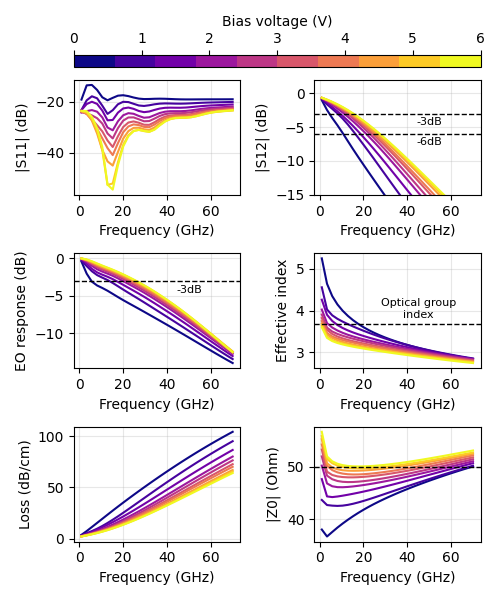

: 

In [ ]:
fig = plt.figure(figsize = (5,6))
gs = fig.add_gridspec(5, 2, height_ratios=[0.1, -0.9, 1, 1, 1])

cax = fig.add_subplot(gs[0, :])
ax_s11 = fig.add_subplot(gs[2, 0])
ax_s12 = fig.add_subplot(gs[2, 1])
ax_eo = fig.add_subplot(gs[3, 0])
ax_neff = fig.add_subplot(gs[3, 1])
ax_loss = fig.add_subplot(gs[4, 0])
ax_Z0 = fig.add_subplot(gs[4, 1])

colors = plt.get_cmap('plasma', len(voltage_idxs))


for ax, data in zip([ax_s11,ax_s12], [S11_values, S12_values]):
    for j, voltage_idx in enumerate(voltage_idxs):
        ax.plot(
            freq_values,
            20*np.log10(np.abs(data[j])),
            color = colors(j),
        )

ax_s12.axhline(-3, color = 'black', linestyle = '--', linewidth = 1)
ax_s12.axhline(-6, color = 'black', linestyle = '--', linewidth = 1)

for j, voltage_idx in enumerate(voltage_idxs):
    ax_eo.plot(
        freq_values,
        EO_values[j],
        color = colors(j),
    )

for j, voltage_idx in enumerate(voltage_idxs):
    ax_neff.plot(
            freq_values,
            neff_values[j],
            color = colors(j),
        )

    ax_loss.plot(
            freq_values,
            loss_values[j],
            color = colors(j),
        )

    ax_Z0.plot(
            freq_values,
            np.abs(Z0_values[j]),
            color = colors(j),
        )

for ax in [ax_s11, ax_s12, ax_eo, ax_neff, ax_loss, ax_Z0]:
    ax.set_xlabel('Frequency (GHz)')
    ax.grid(True, alpha=0.3)

ax_s11.set_ylabel('|S11| (dB)')
ax_s12.set_ylabel('|S12| (dB)')
ax_eo.set_ylabel('EO response (dB)')
ax_neff.set_ylabel('Effective index')
ax_neff.axhline(3.67, color = 'black', linestyle = '--', linewidth = 1)
ax_loss.set_ylabel('Loss (dB/cm)')
ax_Z0.set_ylabel('|Z0| (Ohm)')

ax_Z0.axhline(50, color = 'black', linestyle = '--', linewidth = 1)

ax_eo.axhline(-3, color = 'black', linestyle = '--', linewidth = 1)

mapper = plt.cm.ScalarMappable(cmap=colors)
mapper.set_array(voltage_values)
fig.colorbar(mapper, cax=cax, orientation='horizontal', label='Bias voltage (V)')
cax.xaxis.set_label_position('top')
cax.xaxis.set_ticks_position('top')
ax_s12.set_ylim(-15,2)

for ax in [ax_s11, ax_s12, ax_eo, ax_neff, ax_loss, ax_Z0]:
    ax.set_xticks([0, 20,40,60])

fig.tight_layout()

ax_neff.text(45 , 4.3, 'Optical group\nindex',  va='top', ha='center', fontsize=8)
ax_eo.text(50, -3.5, '-3dB',  va='top', ha='center', fontsize=8)
ax_s12.text(50, -3.5, '-3dB',  va='top', ha='center', fontsize=8)
ax_s12.text(50, -6.5, '-6dB',  va='top', ha='center', fontsize=8)
fig.savefig("../Images/RF_simulation_results.png", dpi=300)